## Front Distance with Matching: Periphery

Using: /Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.5-growth_rates:5e-05,2.5e-05-initial_cells:50-rng_seed:1712031202
Periphery after deduplication: 538
Sampled periphery: 100


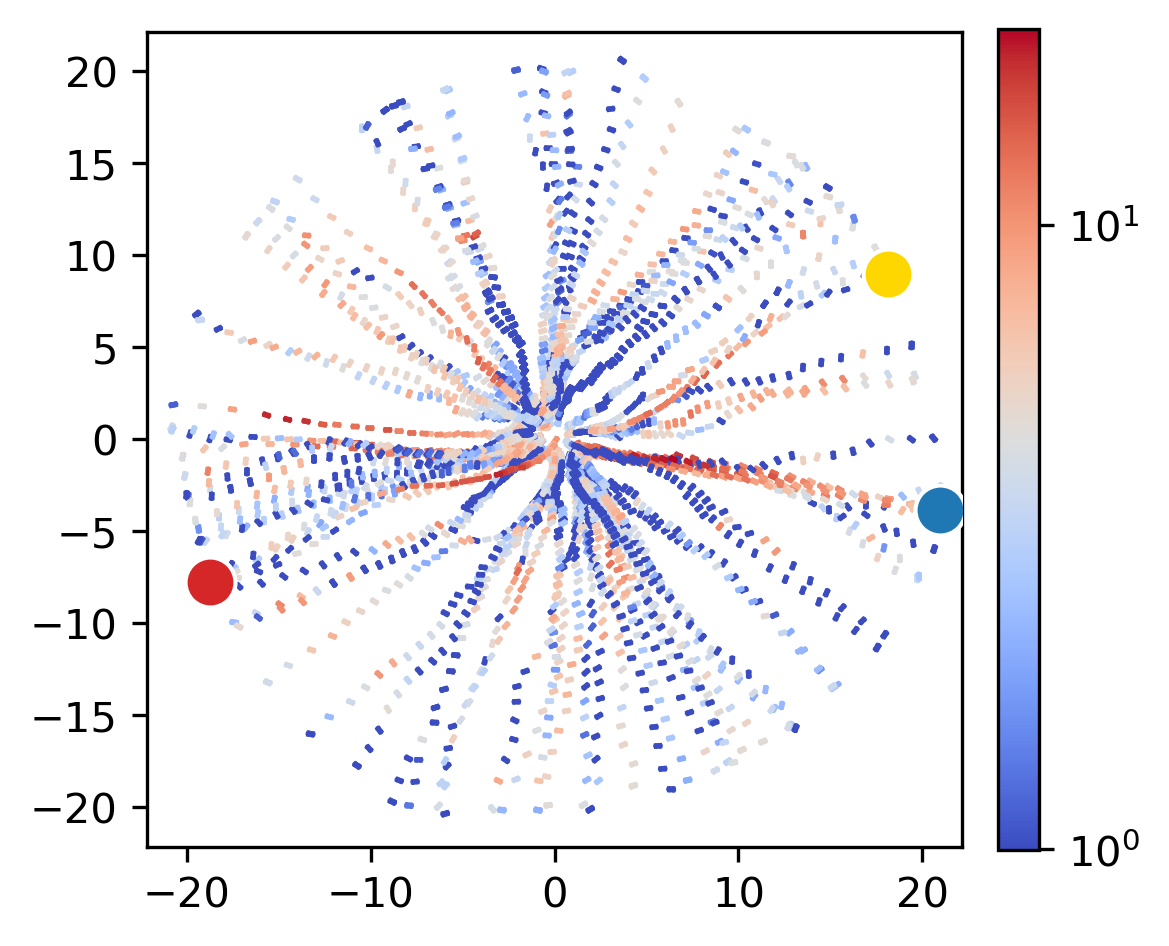

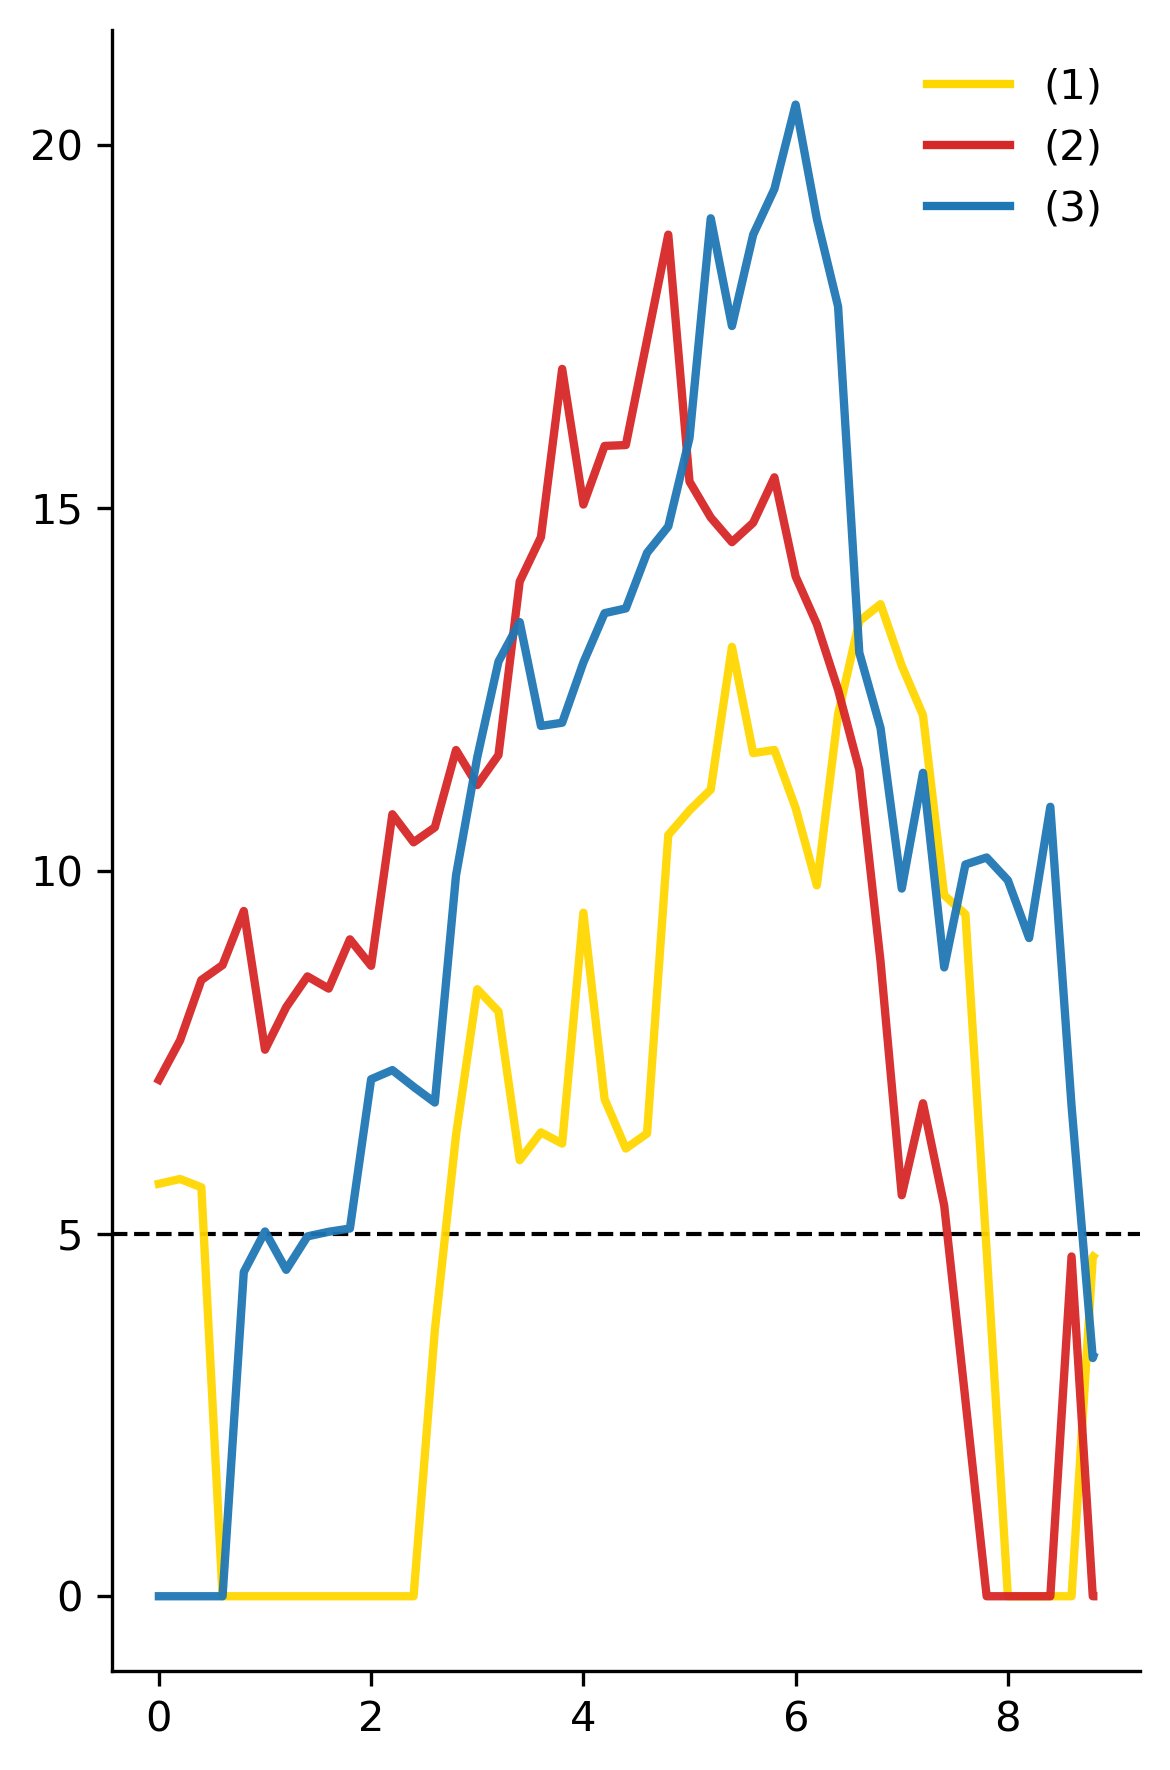

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import matplotlib as mpl
import re

import tools.tracking.ancestors_with_bulk as ancestorTracker
from tools.graphics import snapshots as snaps
from tools.dataAPI.datamodel import DataModel
from routines.parameterTable import parameterTable

#path
BASE_PATH   = "/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10"
OUTPUT_PATH = "/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/investigations"

TARGET_ASP1 = 5.0
TARGET_ASP2 = 10.0
N_BULK      = 1000
SEED        = 5
N_SAMPLE    = 100
N_HIGHLIGHT = 3
DIVISION_TIME       = 2e6
PERIPHERY_THRESHOLD = 0.5
MIN_RUN_LENGTH      = 3


df_params = parameterTable(BASE_PATH)

def extract_aspect_ratios_from_path(path):
    match = re.search(r'(division_lengths|MAR):([\d.]+),([\d.]+)', path)
    if not match:
        return None
    asp1 = round(float(match.group(2)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(2))
    asp2 = round(float(match.group(3)) / 0.1, 0) if match.group(1) == 'division_lengths' else float(match.group(3))
    return asp1, asp2

sample_path = None
for path in df_params.basePath.values:
    try:
        asp1, asp2 = extract_aspect_ratios_from_path(path)
    except ValueError:
        continue
    if (asp1 == TARGET_ASP1 and asp2 == TARGET_ASP2) or (asp1 == TARGET_ASP2 and asp2 == TARGET_ASP1):
        sample_path = path
        break

opts, times = DataModel.extract_times(sample_path)
actual_times = np.array(times, dtype=float)


def deduplicate_by_final_position(trajectories):
    seen = set()
    unique = []
    for traj in trajectories:
        key = (round(float(traj.x[-1]), 3), round(float(traj.y[-1]), 3))
        if key not in seen:
            seen.add(key)
            unique.append(traj)
    return unique

peri_trajectories, _ = ancestorTracker.fetch_trajectories_all(
    sample_path, n_bulk=N_BULK, seed=SEED, filter_t0=False
)
peri_trajectories = deduplicate_by_final_position(peri_trajectories)

rng = np.random.default_rng(SEED)
peri_idx = rng.choice(len(peri_trajectories), size=min(N_SAMPLE, len(peri_trajectories)), replace=False).tolist()
peri_sample = [peri_trajectories[i] for i in peri_idx]


def select_high_variance_spatially_spread(trajectories, n, min_sep=2.0):
    variances = [np.var(t.front_displacement / 0.1) for t in trajectories]
    candidates = np.argsort(variances)[::-1].tolist()

    selected = []
    selected_positions = []

    for idx in candidates:
        x_end = float(trajectories[idx].x[-1])
        y_end = float(trajectories[idx].y[-1])
        too_close = any(
            np.hypot(x_end - xp, y_end - yp) < min_sep
            for xp, yp in selected_positions
        )
        if not too_close:
            selected.append(idx)
            selected_positions.append((x_end, y_end))
        if len(selected) == n:
            break

    return selected

hi_peri = select_high_variance_spatially_spread(peri_sample, N_HIGHLIGHT, min_sep=2.0)

HIGHLIGHT_COLORS = ["gold", "tab:red", "tab:blue", "tab:orange"]


def draw_snapshot(ax, trajectories, highlight_indices=None, cmap="coolwarm"):
    all_d = np.concatenate([t.front_displacement / 0.1 for t in trajectories])

   
    pos_vals = all_d[all_d > 0]
    gmin = pos_vals.min()
    gmax = all_d.max()
    if gmin == gmax:
        gmax = gmin * 10

    cm = mpl.colormaps[cmap]
    global_norm = mcolors.LogNorm(vmin=gmin, vmax=gmax, clip=True)
    highlight_indices = set(highlight_indices) if highlight_indices else set()
    hi_sorted = sorted(highlight_indices)

    for idx, traj in enumerate(trajectories):
        x, y, ex, ey = traj.x, traj.y, traj.ex, traj.ey
        r = traj.front_displacement / 0.1
        colors = cm(global_norm(r))
        R = 0.1 / 2
        l = 6 * R * np.ones(x.size)
        snaps.iterateRods(ax, colors, x, y, ex, ey, l, None, R, resp=0.01)

        if idx in highlight_indices:
            rank = hi_sorted.index(idx)
            dot_color = HIGHLIGHT_COLORS[rank]
            ax.plot(float(x[-1]), float(y[-1]), 'o',
                    color=dot_color, markersize=12,
                    markeredgecolor='white', markeredgewidth=1.0,
                    zorder=6)

    all_x = np.concatenate([t.x for t in trajectories])
    all_y = np.concatenate([t.y for t in trajectories])
    pad = 1.0
    lim = max(abs(all_x.min()), abs(all_x.max()),
              abs(all_y.min()), abs(all_y.max())) + pad
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")

    return cm, [gmin, gmax]


import matplotlib.ticker as mticker

def apply_colorbar(fig, ax, cm, vrange):
    v_min, v_max = vrange

    norm = mcolors.LogNorm(vmin=v_min, vmax=v_max)

    sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)

    
    cb.ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
    cb.ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext())

    cb.ax.yaxis.set_minor_locator(mticker.NullLocator())

    return cb


def draw_timeseries(ax, trajectories, highlight_indices=None):
    highlight_indices = sorted(highlight_indices) if highlight_indices else []

    legend_handles = []
    for rank, idx in enumerate(highlight_indices):
        traj = trajectories[idx]
        n = len(traj.front_displacement)
        t_scaled = actual_times[:n] / DIVISION_TIME
        dist = traj.front_displacement / 0.1
        color = HIGHLIGHT_COLORS[rank]
        ax.plot(t_scaled, dist, color=color, linewidth=2, alpha=0.95, zorder=3)
        legend_handles.append(
            mlines.Line2D([], [], color=color, linewidth=2, label=f"({rank+1})")
        )

    ax.axhline(PERIPHERY_THRESHOLD / 0.1, color='black', linestyle='--',
               linewidth=1, zorder=1)
    ax.spines[['top', 'right']].set_visible(False)
    if legend_handles:
        ax.legend(handles=legend_handles, fontsize=10, frameon=False)


fig_snap, ax_snap = plt.subplots(figsize=(4, 6), dpi=300)
fig_snap.patch.set_facecolor("white")
ax_snap.set_facecolor("white")

cm, vrange = draw_snapshot(ax_snap, peri_sample, highlight_indices=hi_peri)
apply_colorbar(fig_snap, ax_snap, cm, vrange)

plt.tight_layout()
plt.show()


fig_ts, ax_ts = plt.subplots(figsize=(4, 6), dpi=300)
fig_ts.patch.set_facecolor("white")
ax_ts.set_facecolor("white")

draw_timeseries(ax_ts, peri_sample, highlight_indices=hi_peri)
ax_ts.tick_params(axis='both', which='major', labelsize=10)

plt.tight_layout()
plt.show()


## Same for Bulk Cells

Using: /Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.5-growth_rates:5e-05,2.5e-05-initial_cells:50-rng_seed:1712031202
Bulk after deduplication: 1000
Sampled bulk: 100


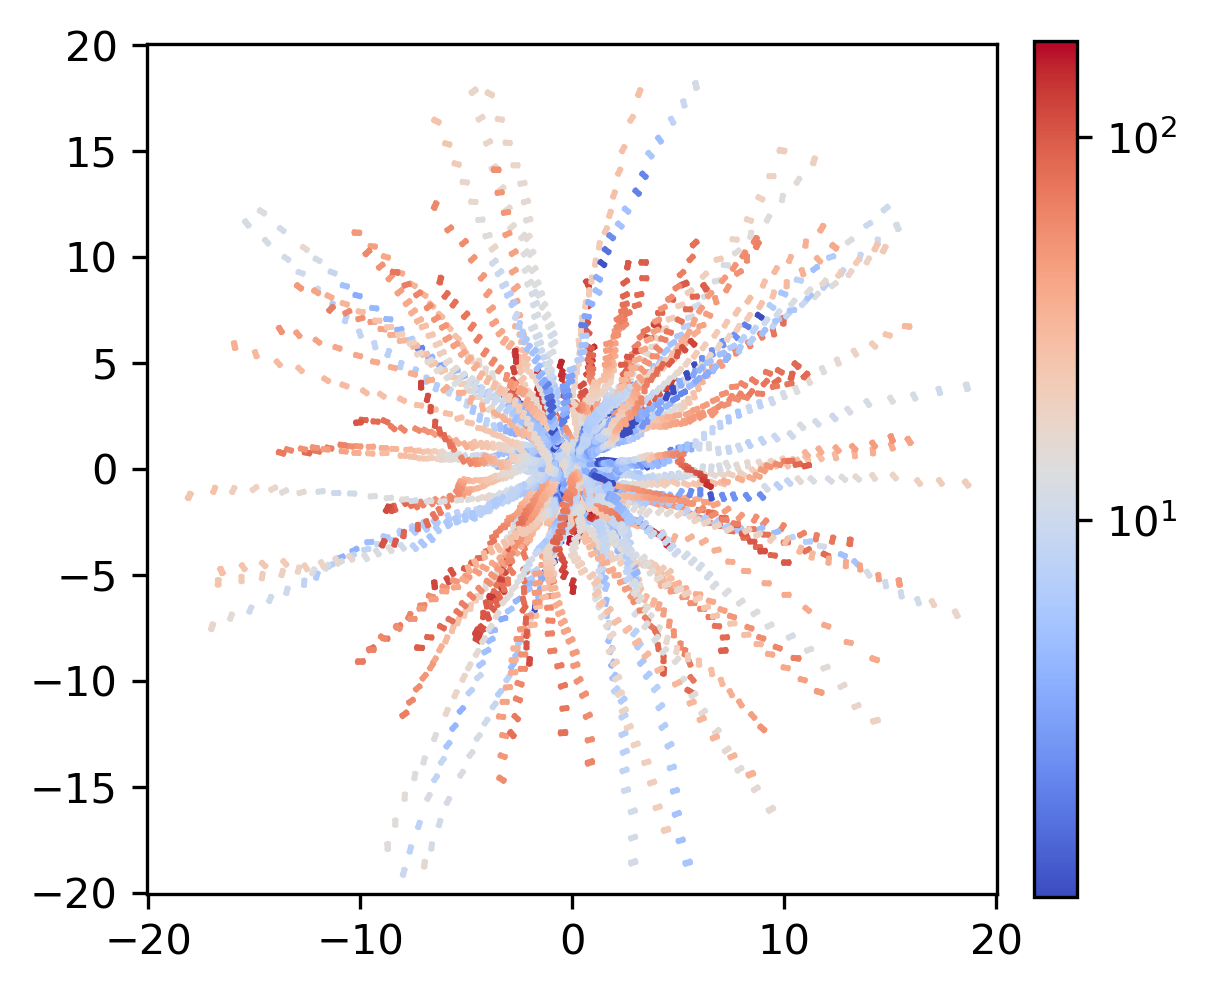

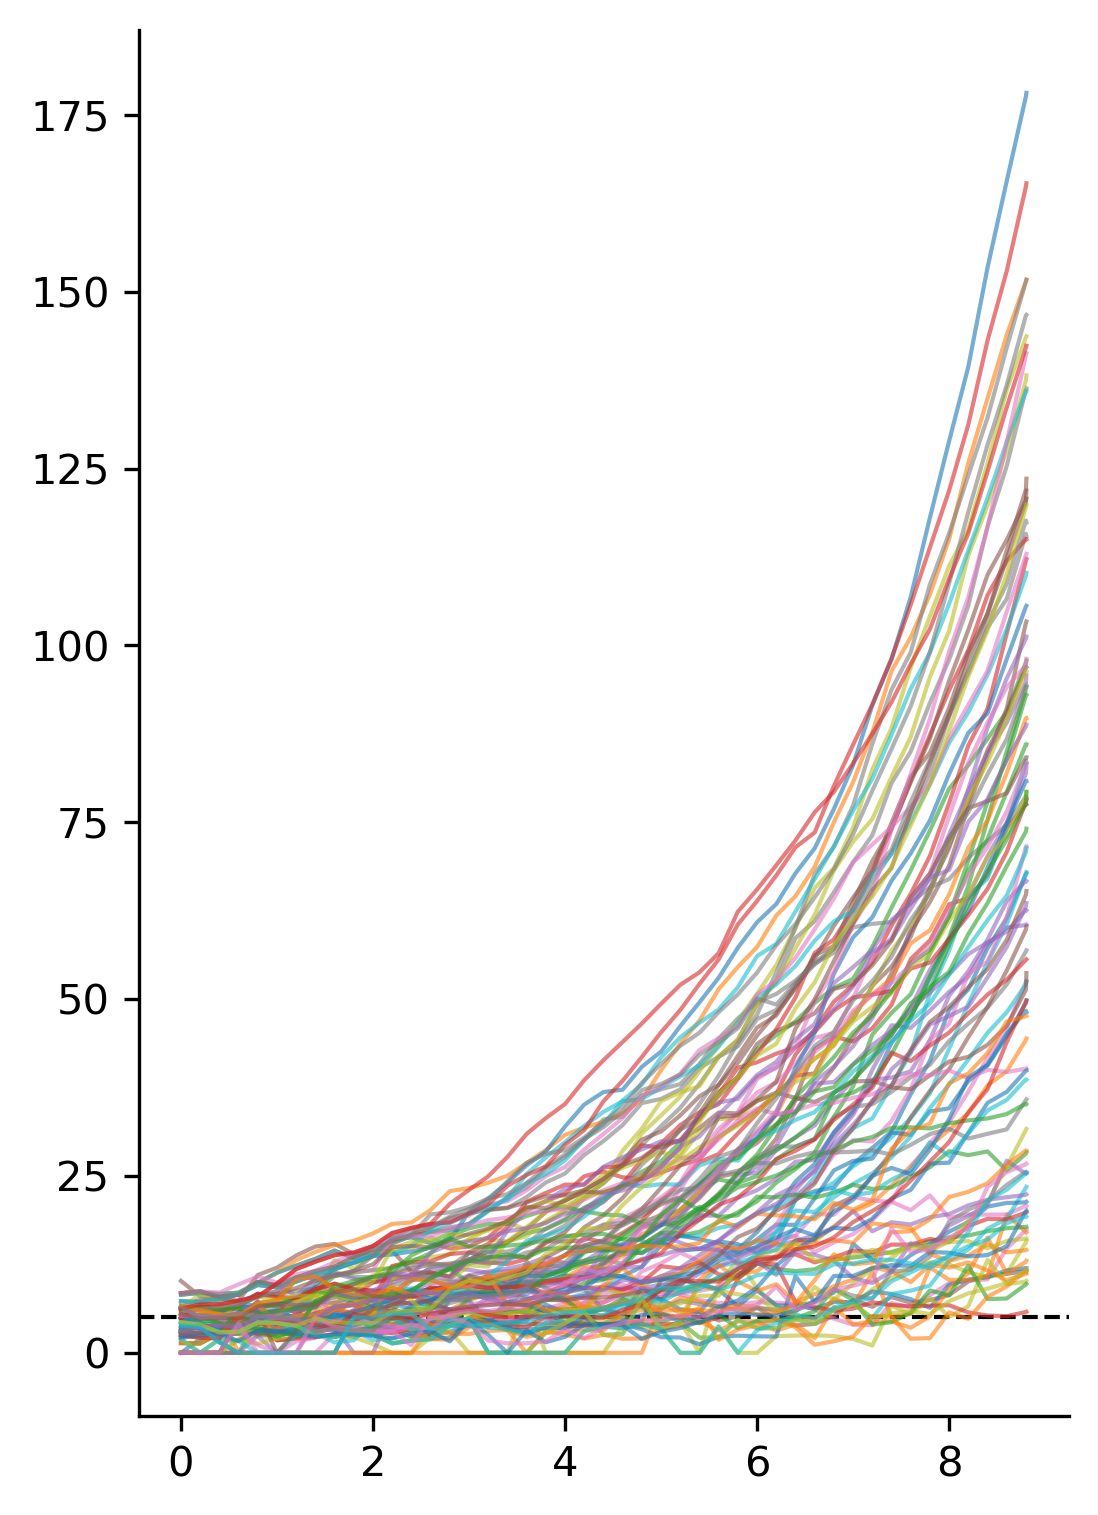

<Figure size 640x480 with 0 Axes>

Saved.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib as mpl
import re

import tools.tracking.ancestors_with_bulk as ancestorTracker
from tools.graphics import snapshots as snaps
from tools.dataAPI.datamodel import DataModel
from routines.parameterTable import parameterTable


BASE_PATH   = "/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10"
OUTPUT_PATH = "/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/investigations"

TARGET_ASP1 = 5.0
TARGET_ASP2 = 10.0
N_BULK      = 1000
SEED        = 70
N_SAMPLE    = 100
DIVISION_TIME       = 2e6
PERIPHERY_THRESHOLD = 0.5
MIN_RUN_LENGTH      = 3


df_params = parameterTable(BASE_PATH)


sample_path = None
for path in df_params.basePath.values:
    try:
        asp1, asp2 = extract_aspect_ratios_from_path(path)
    except ValueError:
        continue
    if (asp1 == TARGET_ASP1 and asp2 == TARGET_ASP2) or (asp1 == TARGET_ASP2 and asp2 == TARGET_ASP1):
        sample_path = path
        break

opts, times = DataModel.extract_times(sample_path)
actual_times = np.array(times, dtype=float)


def deduplicate_by_final_position(trajectories):
    seen = set()
    unique = []
    for traj in trajectories:
        key = (round(float(traj.x[-1]), 3), round(float(traj.y[-1]), 3))
        if key not in seen:
            seen.add(key)
            unique.append(traj)
    return unique

peri_trajectories, bulk_trajectories = ancestorTracker.fetch_trajectories_all(
    sample_path, n_bulk=N_BULK, seed=SEED, filter_t0=False, lineage_filter=False
)

bulk_trajectories = deduplicate_by_final_position(bulk_trajectories)

rng = np.random.default_rng(SEED)
bulk_idx = rng.choice(
    len(bulk_trajectories),
    size=min(N_SAMPLE, len(bulk_trajectories)),
    replace=False
).tolist()

bulk_sample = [bulk_trajectories[i] for i in bulk_idx]

import matplotlib.ticker as mticker

def apply_colorbar(fig, ax, cm, vrange):
    v_min, v_max = vrange

    norm = mcolors.LogNorm(vmin=v_min, vmax=v_max)

    sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)

    
    cb.ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
    cb.ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext())

    
    cb.ax.yaxis.set_minor_locator(mticker.NullLocator())

    return cb


def draw_snapshot(ax, trajectories, highlight_indices=None, cmap="coolwarm"):
    all_d = np.concatenate([t.front_displacement / 0.1 for t in trajectories])

    pos_vals = all_d[all_d > 0]
    gmin = pos_vals.min()
    gmax = all_d.max()
    if gmin == gmax:
        gmax = gmin * 10

    cm = mpl.colormaps[cmap]
    global_norm = mcolors.LogNorm(vmin=gmin, vmax=gmax, clip=True)
    highlight_indices = set(highlight_indices) if highlight_indices else set()
    hi_sorted = sorted(highlight_indices)

    for idx, traj in enumerate(trajectories):
        x, y, ex, ey = traj.x, traj.y, traj.ex, traj.ey
        r = traj.front_displacement / 0.1
        colors = cm(global_norm(r))
        R = 0.1 / 2
        l = 6 * R * np.ones(x.size)
        snaps.iterateRods(ax, colors, x, y, ex, ey, l, None, R, resp=0.01)

        if idx in highlight_indices:
            rank = hi_sorted.index(idx)
            dot_color = HIGHLIGHT_COLORS[rank]
            ax.plot(float(x[-1]), float(y[-1]), 'o',
                    color=dot_color, markersize=12,
                    markeredgecolor='white', markeredgewidth=1.0,
                    zorder=6)

    all_x = np.concatenate([t.x for t in trajectories])
    all_y = np.concatenate([t.y for t in trajectories])
    pad = 1.0
    lim = max(abs(all_x.min()), abs(all_x.max()),
              abs(all_y.min()), abs(all_y.max())) + pad
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")

    return cm, [gmin, gmax]


def draw_timeseries(ax, trajectories):
    for traj in trajectories:
        n = len(traj.front_displacement)
        t_scaled = actual_times[:n] / DIVISION_TIME
        dist = traj.front_displacement / 0.1
        ax.plot(t_scaled, dist, linewidth=1, alpha=0.6, zorder=2)

    ax.axhline(PERIPHERY_THRESHOLD / 0.1, color='black', linestyle='--',
               linewidth=1, zorder=1)
    ax.spines[['top', 'right']].set_visible(False)


fig_snap, ax_snap = plt.subplots(figsize=(4, 6), dpi=300)
cm, vrange = draw_snapshot(ax_snap, bulk_sample)
apply_colorbar(fig_snap, ax_snap, cm, vrange)
plt.show()


fig_ts, ax_ts = plt.subplots(figsize=(4, 6), dpi=300)
draw_timeseries(ax_ts, bulk_sample)
plt.show()

plt.tight_layout()
plt.show()
